# Perceiver IO Population-Vector Trajectory Decoder

Decode 3D flight trajectories from a **single instantaneous population vector** (pseudo-population predicted firing rates). Two variants:
- **Relative-time**: query grid centered at t=0 (moment of sampling), ±T_max
- **Absolute-time**: query grid from flight onset (t=0) to T_max

Compare with the seq-to-seq transformer decoder from `decode-position-comparison.ipynb`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import copy
import pickle

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import Dataset, DataLoader
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, roc_auc_score
import optuna
import tqdm
%matplotlib inline

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.perceiver import PerceiverIOTrajectoryDecoder, PerceiverIOConfig
from digitalbat.models.layers import ELU1
from digitalbat.utility.utils import set_random_state

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'device: {device}')

device: cuda


## 1. Load Data + Encoder Model
Same data config as `preprocess-data-v0j-share.ipynb`.

In [2]:
from digitalbat.datasets.defaults import make_data_config

data_config = make_data_config()
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
dt = data_config['bin_width']
print(f'behavior_dim={behavior_dim}, sessions={len(unit_num_dict)}')
print(f'Total neurons: {sum(unit_num_dict.values())}')


  Acceleration filter: removed 4/37 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 4/136 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 14/154 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 6/131 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 2/79 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 2/78 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 3/80 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 2/145 flights (peak |acc| > 40 m/s²)
behavior_dim=3, sessions=18
Total neurons: 3369


In [3]:
# Load the trained bat_former encoder (same config as preprocess notebook)
from digitalbat.models.former_defaults import (
    DEFAULT_LR, DEFAULT_WEIGHT_DECAY, make_model_config, make_model_name,
)

lr_transformer = DEFAULT_LR
weight_decay_transformer = DEFAULT_WEIGHT_DECAY
model_name = make_model_name(seed, lr_transformer, weight_decay_transformer)

model_config = make_model_config(behavior_dim, unit_num_dict, meta_info_dict)
bat_former = Bat_Transformer(**model_config)
bat_former.load_state_dict(torch.load(model_name, map_location=device, weights_only=True))
bat_former = bat_former.to(device)
bat_former.eval()
print(f'Loaded encoder from {model_name}')


Loaded encoder from ./out/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02.pth


## 2. Extract Pseudo-Population Vectors + Flight Trajectories
For each flight in each split, run the encoder to get predicted firing rates (pseudo-population) per timepoint, and collect the corresponding 3D positions.

In [4]:
def build_super_ensemble(bat_former, latents, session_order, device):
    """Map latent vectors to pseudo-population rates by concatenating readouts."""
    final_act = bat_former.final_activation
    dtype_ref = next(bat_former.parameters()).dtype
    lat_t = torch.from_numpy(latents).to(device=device, dtype=dtype_ref)
    parts = []
    with torch.no_grad():
        for sn in session_order:
            p = bat_former.readouts[sn](lat_t)
            p = final_act(p).detach().cpu().numpy()
            parts.append(p)
    return np.concatenate(parts, axis=1)


def extract_flights(dataloaders, bat_former, meta_info_dict, tier, device, dt):
    """Extract per-flight data: pseudo-population vectors + 3D trajectories.

    Returns a list of dicts, one per flight:
        {'pv': (T_flight, N_pseudo), 'xyz': (T_flight, 3),
         'session': str, 'flight_id': int, 'flight_type': int}
    """
    bm_all = meta_info_dict['behavior_mean']
    bs_all = meta_info_dict['behavior_std']
    session_order = list(dataloaders[tier].keys())

    # First pass: collect latents per flight per session
    flight_data_raw = []  # list of (latent, xyz, session, flight_id, flight_type)

    for sn in session_order:
        bm, bs = bm_all[sn], bs_all[sn]
        captured = []
        hook = bat_former.readouts[sn].register_forward_pre_hook(
            lambda mod, inp: captured.append(inp[0].detach().cpu())
        )
        with torch.no_grad():
            for batch in dataloaders[tier][sn]:
                _ = bat_former(sn, batch.behavior.to(device), batch.mask.to(device))
                lat = captured[-1]  # (B, T, latent_dim)
                M = batch.mask.numpy()
                X = batch.behavior.numpy()
                fpi = batch.flight_path_index.numpy()
                fti = batch.flight_type_index.numpy()

                for b in range(M.shape[0]):
                    valid = M[b] == 1.0
                    n_v = int(valid.sum())
                    if n_v == 0:
                        continue
                    pos_full = X[b, :, :3] * bs[0, 0, :3] + bm[0, 0, :3]
                    flight_data_raw.append({
                        'latent': lat[b, valid].numpy(),
                        'xyz': pos_full[valid],
                        'session': sn,
                        'flight_id': int(fpi[b]),
                        'flight_type': int(fti[b]),
                    })
        hook.remove()

    # Second pass: convert latents to pseudo-population predictions
    all_latents = np.concatenate([f['latent'] for f in flight_data_raw], axis=0)
    all_preds = build_super_ensemble(bat_former, all_latents, session_order, device)

    # Split back into per-flight arrays
    flights = []
    offset = 0
    for fd in flight_data_raw:
        n = fd['latent'].shape[0]
        flights.append({
            'pv': all_preds[offset:offset + n],  # (T_flight, N_pseudo)
            'xyz': fd['xyz'],                     # (T_flight, 3)
            'session': fd['session'],
            'flight_id': fd['flight_id'],
            'flight_type': fd['flight_type'],
        })
        offset += n

    return flights


flights_train = extract_flights(dataloaders, bat_former, meta_info_dict, 'train', device, dt)
flights_valid = extract_flights(dataloaders, bat_former, meta_info_dict, 'valid', device, dt)
flights_test  = extract_flights(dataloaders, bat_former, meta_info_dict, 'test',  device, dt)

n_pseudo = flights_train[0]['pv'].shape[1]
print(f'Pseudo-population size: {n_pseudo}')
print(f'Flights — train: {len(flights_train)}, valid: {len(flights_valid)}, test: {len(flights_test)}')
print(f'Flight lengths — min: {min(f["xyz"].shape[0] for f in flights_train)}, '
      f'max: {max(f["xyz"].shape[0] for f in flights_train)}, '
      f'median: {np.median([f["xyz"].shape[0] for f in flights_train]):.0f}')

Pseudo-population size: 3369
Flights — train: 1231, valid: 255, test: 284
Flight lengths — min: 11, max: 119, median: 24


## 3. PV Trajectory Dataset

In [5]:
class PVTrajectoryDataset(Dataset):
    """Dataset yielding (population_vector, position_targets, validity_mask, t_sample, flight_idx).

    At init, for each flight we sample `samples_per_flight` random t_sample values.
    Call `resample()` to re-draw t_sample values each epoch (for training).
    """

    def __init__(self, flights, time_mode, T_max, dt, samples_per_flight=5, rng=None):
        self.flights = flights
        self.time_mode = time_mode
        self.T_max = T_max
        self.dt = dt
        self.samples_per_flight = samples_per_flight
        self.rng = rng or np.random.default_rng(42)

        if time_mode == 'relative':
            self.query_times = np.arange(-T_max, T_max + dt / 2, dt)
        else:
            self.query_times = np.arange(0, T_max + dt / 2, dt)
        self.O = len(self.query_times)
        # Precompute integer query offsets once — kills the per-getitem Python loop.
        self.query_offsets = np.round(self.query_times / dt).astype(np.int64)

        self._build_examples()

    def _build_examples(self):
        self.examples = []
        for fi, flight in enumerate(self.flights):
            T_flight = flight['xyz'].shape[0]
            t_samples = self.rng.choice(T_flight, size=self.samples_per_flight, replace=True)
            for ts in t_samples:
                self.examples.append((fi, int(ts)))

    def resample(self):
        self._build_examples()

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        fi, t_sample = self.examples[idx]
        flight = self.flights[fi]
        trajectory = flight['xyz']               # (T_flight, 3)
        T_flight = trajectory.shape[0]

        if self.time_mode == 'relative':
            flight_indices = t_sample + self.query_offsets
        else:
            flight_indices = self.query_offsets

        valid = (flight_indices >= 0) & (flight_indices < T_flight)
        clamped = np.clip(flight_indices, 0, T_flight - 1)
        position_targets = trajectory[clamped].astype(np.float32)
        position_targets[~valid] = 0.0
        validity_mask = valid.astype(np.float32)

        pv = flight['pv'][t_sample].astype(np.float32, copy=False)

        return (
            torch.from_numpy(pv),
            torch.from_numpy(position_targets),
            torch.from_numpy(validity_mask),
            t_sample,
            fi,
        )

In [6]:
# Compute T_max from actual flight durations
all_flight_lens = [f['xyz'].shape[0] for f in flights_train + flights_valid + flights_test]
T_max_bins = max(all_flight_lens)
T_max = T_max_bins * dt
print(f'T_max = {T_max:.1f} s ({T_max_bins} bins)')
print(f'Flight length distribution (bins): '
      f'min={min(all_flight_lens)}, p25={np.percentile(all_flight_lens, 25):.0f}, '
      f'median={np.median(all_flight_lens):.0f}, p75={np.percentile(all_flight_lens, 75):.0f}, '
      f'max={max(all_flight_lens)}')

T_max = 13.9 s (139 bins)
Flight length distribution (bins): min=10, p25=21, median=23, p75=38, max=139


## 4. Training Infrastructure

In [7]:
def train_perceiver(
    config, flights_train, flights_valid, device, trial=None, verbose=True,
    samples_per_flight_train=5, samples_per_flight_val=10,
    random_seed=1, num_workers=2,
):
    """Train a PerceiverIOTrajectoryDecoder. Returns (best_val_r2, best_state_dict, history)."""
    set_random_state(random_seed)

    train_ds = PVTrajectoryDataset(
        flights_train, config.time_mode, config.T_max, config.dt,
        samples_per_flight=samples_per_flight_train,
        rng=np.random.default_rng(random_seed),
    )
    val_ds = PVTrajectoryDataset(
        flights_valid, config.time_mode, config.T_max, config.dt,
        samples_per_flight=samples_per_flight_val,
        rng=np.random.default_rng(random_seed + 1),
    )

    # num_workers > 0 forks workers per epoch with the latest examples list,
    # so resample() before each iter() still takes effect. Persistent workers
    # would defeat that.
    train_loader = DataLoader(train_ds, batch_size=config.batch_size, shuffle=True,
                              drop_last=False, num_workers=num_workers,
                              pin_memory=(device == 'cuda'))
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False,
                            num_workers=num_workers,
                            pin_memory=(device == 'cuda'))

    model = PerceiverIOTrajectoryDecoder(config).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay,
    )

    # Cosine schedule with warmup
    total_steps = config.max_epochs * len(train_loader)

    def lr_lambda(step):
        if step < config.warmup_steps:
            return step / max(config.warmup_steps, 1)
        progress = (step - config.warmup_steps) / max(total_steps - config.warmup_steps, 1)
        return 0.5 * (1 + np.cos(np.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    best_val_r2 = -np.inf
    best_weights = None
    patience_counter = 0
    history = {'train_loss': [], 'val_r2': [], 'val_pos_loss': [], 'val_valid_auc': []}

    iterator = tqdm.tqdm(range(config.max_epochs), desc='Training') if verbose else range(config.max_epochs)
    for epoch in iterator:
        # Resample t_sample values each epoch
        train_ds.resample()

        model.train()
        epoch_loss = 0.0
        n_batches = 0
        for pv, pos_tgt, vmask, _, _ in train_loader:
            pv, pos_tgt, vmask = pv.to(device), pos_tgt.to(device), vmask.to(device)
            pos_pred, valid_logit, _, _ = model(pv)
            loss, _, _ = model.compute_loss(pos_pred, valid_logit, pos_tgt, vmask)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.gradient_clip)
            optimizer.step()
            scheduler.step()

            epoch_loss += loss.item()
            n_batches += 1

        history['train_loss'].append(epoch_loss / max(n_batches, 1))

        # Validation
        model.eval()
        all_pos_true, all_pos_pred = [], []
        all_valid_true, all_valid_logit = [], []
        with torch.no_grad():
            for pv, pos_tgt, vmask, _, _ in val_loader:
                pv, pos_tgt, vmask = pv.to(device), pos_tgt.to(device), vmask.to(device)
                pos_pred, valid_logit, _, _ = model(pv)
                mask_bool = vmask.bool()
                all_pos_true.append(pos_tgt[mask_bool].cpu().numpy())
                all_pos_pred.append(pos_pred[mask_bool].cpu().numpy())
                all_valid_true.append(vmask.cpu().numpy().ravel())
                all_valid_logit.append(valid_logit.cpu().numpy().ravel())

        pos_true_np = np.concatenate(all_pos_true)
        pos_pred_np = np.concatenate(all_pos_pred)
        val_r2 = float(r2_score(pos_true_np, pos_pred_np))
        val_pos_loss = float(np.mean((pos_true_np - pos_pred_np) ** 2))

        vt = np.concatenate(all_valid_true)
        vl = np.concatenate(all_valid_logit)
        val_auc = float(roc_auc_score(vt, vl)) if len(np.unique(vt)) > 1 else 0.5

        history['val_r2'].append(val_r2)
        history['val_pos_loss'].append(val_pos_loss)
        history['val_valid_auc'].append(val_auc)

        if trial is not None:
            trial.report(val_r2, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if val_r2 > best_val_r2:
            best_val_r2 = val_r2
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config.patience:
                if verbose:
                    print(f'Early stopping at epoch {epoch + 1}')
                break

        if verbose and hasattr(iterator, 'set_postfix'):
            iterator.set_postfix(r2=f'{val_r2:.4f}', best=f'{best_val_r2:.4f}',
                                 auc=f'{val_auc:.3f}')

    return best_val_r2, best_weights, history

## 5. Optuna Hyperparameter Search

In [8]:
N_OPTUNA_TRIALS = 200


def suggest_hyperparams(trial, time_mode, n_neurons, T_max, *,
                        max_epochs=80, warmup_steps=100):
    """Build a PerceiverIOConfig from an Optuna trial.

    The default ``max_epochs=80`` / ``warmup_steps=100`` are tuned for the
    *search* — for final training, override with the original 200/500.
    """
    C = trial.suggest_categorical('C', [1, 2, 4, 8, 16])
    L = trial.suggest_categorical('L', [4, 8, 16, 32])
    D = trial.suggest_categorical('D', [16, 32, 64])
    # Search d_head (per-head channel size) instead of n_heads — keeps the
    # categorical distribution static across trials, satisfying Optuna's
    # "no dynamic value space" constraint. n_heads = D // d_head.
    d_head = trial.suggest_categorical('d_head', [4, 8, 16, 32])
    if d_head > D:
        raise optuna.TrialPruned()
    n_heads = D // d_head
    n_process_layers = trial.suggest_int('n_process_layers', 1, 8)
    D_ff_multiplier = trial.suggest_categorical('D_ff_multiplier', [1, 2, 4])
    n_fourier_bands = trial.suggest_categorical('n_fourier_bands', [8, 16, 32])
    learning_rate = trial.suggest_float('learning_rate', 1e-5, 1e-2, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-5, 0.1, log=True)
    dropout_rate = trial.suggest_float('dropout_rate', 0.0, 0.5)
    lambda_valid = trial.suggest_float('lambda_valid', 0.01, 1.0)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128, 256])

    return PerceiverIOConfig(
        n_neurons=n_neurons, C=C, L=L, D=D, n_heads=n_heads,
        n_process_layers=n_process_layers, D_ff_multiplier=D_ff_multiplier,
        time_mode=time_mode, T_max=T_max, dt=dt,
        n_fourier_bands=n_fourier_bands, learning_rate=learning_rate,
        weight_decay=weight_decay, dropout_rate=dropout_rate,
        lambda_valid=lambda_valid, batch_size=batch_size,
        max_epochs=max_epochs, warmup_steps=warmup_steps,
    )


def make_objective(time_mode):
    def objective(trial):
        config = suggest_hyperparams(trial, time_mode, n_pseudo, T_max)
        # verbose=True → tqdm bar with r2/best/auc updates per epoch.
        val_r2, _, _ = train_perceiver(
            config, flights_train, flights_valid, device,
            trial=trial, verbose=True,
        )
        return val_r2
    return objective

In [9]:
os.makedirs('./out', exist_ok=True)


def _trial_callback(study, trial):
    """One-line per-trial summary so progress is visible without flooding logs."""
    if trial.state == optuna.trial.TrialState.COMPLETE:
        best = study.best_value
        print(f'  trial {trial.number}: R²={trial.value:.4f}  best={best:.4f}  params={trial.params}')
    elif trial.state == optuna.trial.TrialState.PRUNED:
        last = trial.intermediate_values
        last_r2 = list(last.values())[-1] if last else float('nan')
        print(f'  trial {trial.number}: PRUNED at epoch {len(last)} (last R²={last_r2:.4f})')
    elif trial.state == optuna.trial.TrialState.FAIL:
        print(f'  trial {trial.number}: FAIL')


studies = {}
for mode in ('relative', 'absolute'):
    study_path = f'./out/perceiver_{mode}_seed_{seed}_optuna.pkl'

    if os.path.exists(study_path):
        with open(study_path, 'rb') as f:
            studies[mode] = pickle.load(f)
        print(f'{mode}: loaded study with {len(studies[mode].trials)} trials')
    else:
        studies[mode] = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=20),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=20),
        )

    remaining = max(0, N_OPTUNA_TRIALS - len(studies[mode].trials))
    if remaining > 0:
        # INFO surfaces each trial's outcome; verbose=True in the objective shows per-epoch
        # tqdm bars within a trial. Together they give live within-run progress.
        optuna.logging.set_verbosity(optuna.logging.INFO)
        studies[mode].optimize(
            make_objective(mode), n_trials=remaining,
            show_progress_bar=True, callbacks=[_trial_callback],
        )
        with open(study_path, 'wb') as f:
            pickle.dump(studies[mode], f)

    print(f'{mode}: best val R² = {studies[mode].best_value:.4f}')
    print(f'  best params: {studies[mode].best_params}')

[I 2026-05-01 15:34:14,917] A new study created in memory with name: no-name-b45d04fe-532b-41fd-b091-19cb39a164d7


  0%|          | 0/200 [00:00<?, ?it/s]

Training:  50%|█████     | 40/80 [01:00<01:00,  1.52s/it, auc=0.536, best=-0.0003, r2=-0.0026]


Early stopping at epoch 41
[I 2026-05-01 15:35:16,418] Trial 0 finished with value: -0.00030744075775146484 and parameters: {'C': 2, 'L': 16, 'D': 64, 'd_head': 4, 'n_process_layers': 3, 'D_ff_multiplier': 1, 'n_fourier_bands': 8, 'learning_rate': 0.00012562773503807024, 'weight_decay': 0.0006672367170464204, 'dropout_rate': 0.3925879806965068, 'lambda_valid': 0.20767704433677614, 'batch_size': 256}. Best is trial 0 with value: -0.00030744075775146484.
  trial 0: R²=-0.0003  best=-0.0003  params={'C': 2, 'L': 16, 'D': 64, 'd_head': 4, 'n_process_layers': 3, 'D_ff_multiplier': 1, 'n_fourier_bands': 8, 'learning_rate': 0.00012562773503807024, 'weight_decay': 0.0006672367170464204, 'dropout_rate': 0.3925879806965068, 'lambda_valid': 0.20767704433677614, 'batch_size': 256}


Training: 100%|██████████| 80/80 [01:31<00:00,  1.15s/it, auc=0.961, best=0.2077, r2=0.1805]


...

[I 2026-05-01 22:07:39,464] Trial 197 pruned. 
  trial 197: PRUNED at epoch 21 (last R²=0.1223)


Training:  25%|██▌       | 20/80 [00:27<01:23,  1.40s/it, auc=0.972, best=0.1244, r2=0.1221]


[I 2026-05-01 22:08:07,477] Trial 198 pruned. 
  trial 198: PRUNED at epoch 21 (last R²=0.1193)


Training: 100%|██████████| 80/80 [01:43<00:00,  1.30s/it, auc=0.981, best=0.3126, r2=0.3124]


[I 2026-05-01 22:09:51,480] Trial 199 finished with value: 0.31263265013694763 and parameters: {'C': 4, 'L': 8, 'D': 64, 'd_head': 4, 'n_process_layers': 1, 'D_ff_multiplier': 1, 'n_fourier_bands': 8, 'learning_rate': 0.0018747790298569646, 'weight_decay': 0.004213024502729578, 'dropout_rate': 0.001184260013096173, 'lambda_valid': 0.0974386370537634, 'batch_size': 32}. Best is trial 199 with value: 0.31263265013694763.
  trial 199: R²=0.3126  best=0.3126  params={'C': 4, 'L': 8, 'D': 64, 'd_head': 4, 'n_process_layers': 1, 'D_ff_multiplier': 1, 'n_fourier_bands': 8, 'learning_rate': 0.0018747790298569646, 'weight_decay': 0.004213024502729578, 'dropout_rate': 0.001184260013096173, 'lambda_valid': 0.0974386370537634, 'batch_size': 32}
absolute: best val R² = 0.3126
  best params: {'C': 4, 'L': 8, 'D': 64, 'd_head': 4, 'n_process_layers': 1, 'D_ff_multiplier': 1, 'n_fourier_bands': 8, 'learning_rate': 0.0018747790298569646, 'weight_decay': 0.004213024502729578, 'dropout_rate': 0.001184260

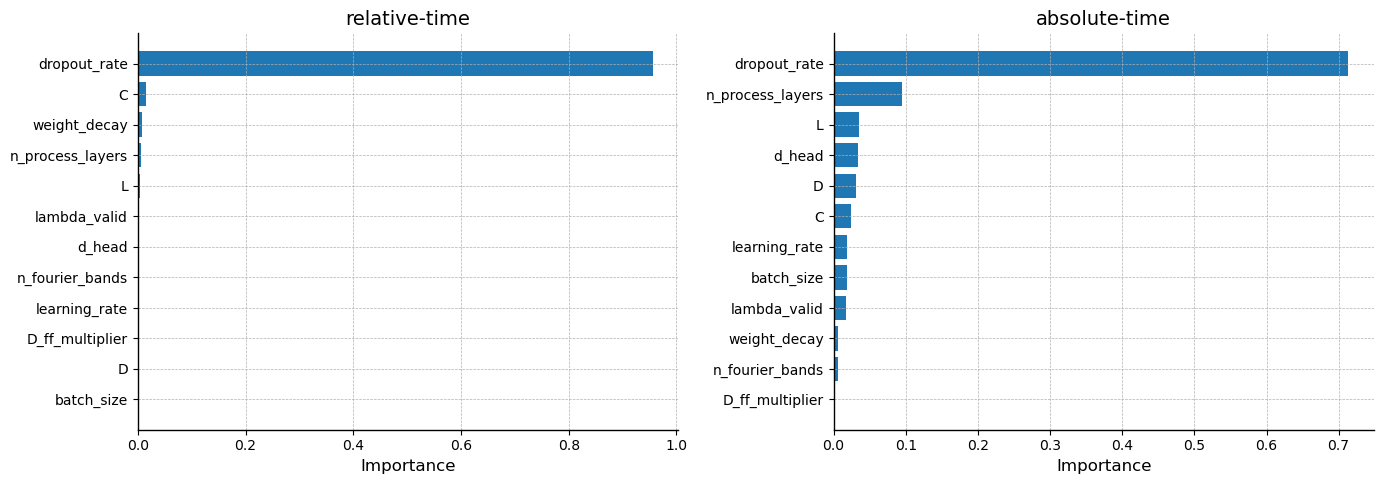

In [10]:
# Hyperparameter importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mode in zip(axes, ('relative', 'absolute')):
    importances = optuna.importance.get_param_importances(studies[mode])
    names = list(importances.keys())
    vals = list(importances.values())
    ax.barh(names, vals)
    ax.set_xlabel('Importance')
    ax.set_title(f'{mode}-time')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Train Best Models (3 seeds)

relative seed 0: loaded from ./out/perceiver_relative_seed_0_best.pth


Training:  30%|███       | 151/500 [05:40<13:08,  2.26s/it, auc=0.978, best=0.3928, r2=0.3504]

Early stopping at epoch 152
relative seed 1: val R² = 0.3928


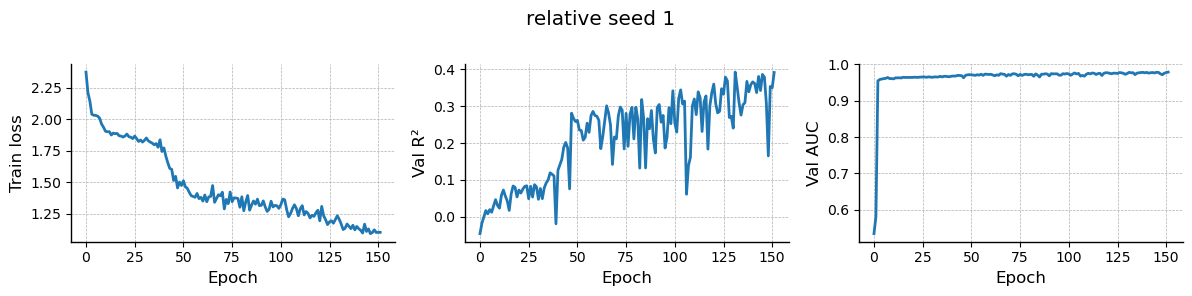

Training:  16%|█▌        | 80/500 [02:37<13:47,  1.97s/it, auc=0.973, best=0.2647, r2=0.1984] 

Early stopping at epoch 81
relative seed 2: val R² = 0.2647


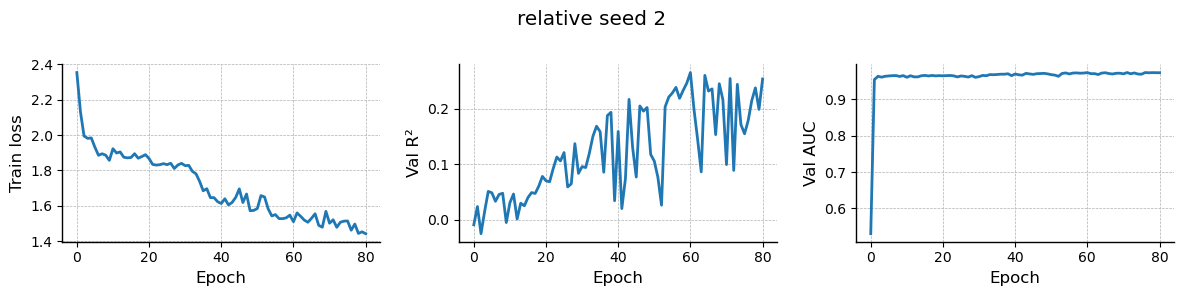

Training:  11%|█▏        | 57/500 [01:20<10:22,  1.40s/it, auc=0.978, best=0.2260, r2=0.2201] 

Early stopping at epoch 58
absolute seed 0: val R² = 0.2260


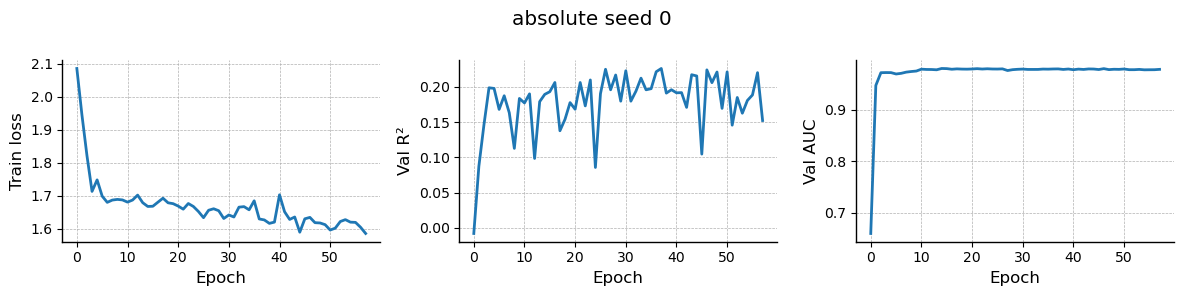

Training:  28%|██▊       | 139/500 [03:09<08:11,  1.36s/it, auc=0.981, best=0.3579, r2=0.3465]

Early stopping at epoch 140
absolute seed 1: val R² = 0.3579


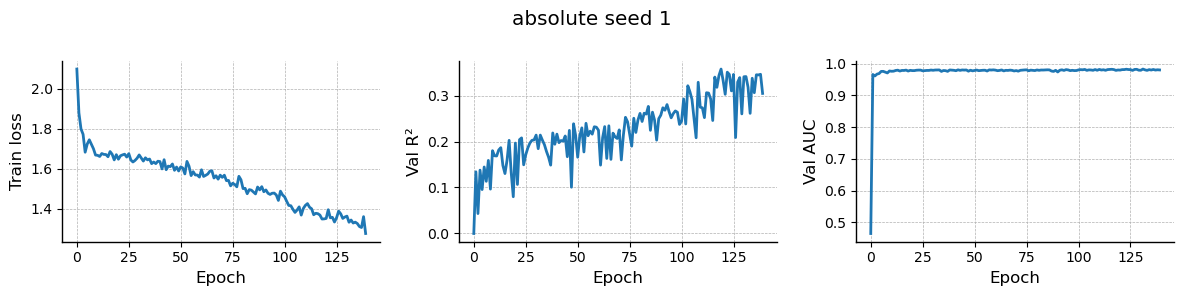

Training:  11%|█         | 53/500 [01:14<10:32,  1.41s/it, auc=0.980, best=0.2265, r2=0.1993] 

Early stopping at epoch 54
absolute seed 2: val R² = 0.2265


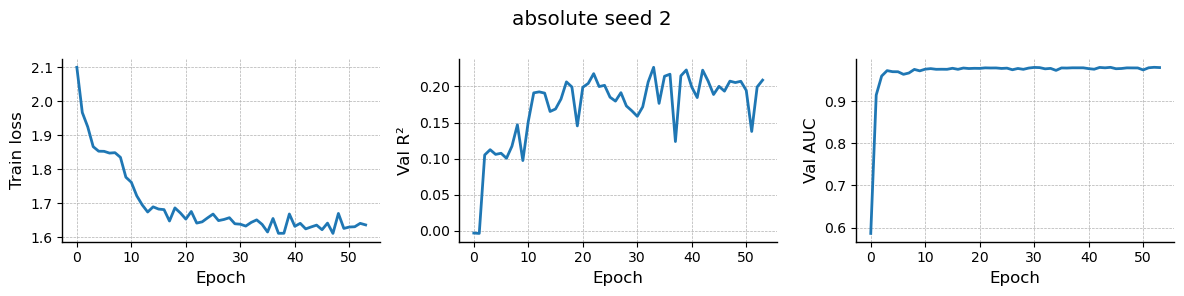

In [12]:
N_SEEDS = 3
best_models = {}  # {mode: [(state_dict, config), ...]}

for mode in ('relative', 'absolute'):
    best_params = studies[mode].best_params
    # Final training uses a longer epoch budget than the search.
    config = suggest_hyperparams(
        optuna.trial.FixedTrial(best_params), mode, n_pseudo, T_max,
        max_epochs=500, warmup_steps=500,
    )
    best_models[mode] = []

    for s in range(N_SEEDS):
        model_path = f'./out/perceiver_{mode}_seed_{s}_best.pth'
        if os.path.exists(model_path):
            weights = torch.load(model_path, map_location=device, weights_only=True)
            best_models[mode].append((weights, config))
            print(f'{mode} seed {s}: loaded from {model_path}')
            continue

        val_r2, weights, history = train_perceiver(
            config, flights_train, flights_valid, device, verbose=True,
            random_seed=s,
        )
        torch.save(weights, model_path)
        best_models[mode].append((weights, config))
        print(f'{mode} seed {s}: val R² = {val_r2:.4f}')

        fig, axes = plt.subplots(1, 3, figsize=(12, 3))
        axes[0].plot(history['train_loss']); axes[0].set_ylabel('Train loss'); axes[0].set_xlabel('Epoch')
        axes[1].plot(history['val_r2']); axes[1].set_ylabel('Val R²'); axes[1].set_xlabel('Epoch')
        axes[2].plot(history['val_valid_auc']); axes[2].set_ylabel('Val AUC'); axes[2].set_xlabel('Epoch')
        plt.suptitle(f'{mode} seed {s}')
        plt.tight_layout()
        plt.show()

## 7. Evaluation

In [13]:
def evaluate_perceiver(model, flights, config, device):
    """Evaluate on test flights. Returns a DataFrame with per-time-query results."""
    model.eval()
    ds = PVTrajectoryDataset(
        flights, config.time_mode, config.T_max, config.dt,
        samples_per_flight=10, rng=np.random.default_rng(0),
    )
    loader = DataLoader(ds, batch_size=256, shuffle=False, num_workers=0)

    records = []
    with torch.no_grad():
        for pv, pos_tgt, vmask, t_sample_batch, fi_batch in loader:
            pv = pv.to(device)
            pos_pred, valid_logit, enc_attn, dec_attn = model(pv)
            pos_pred = pos_pred.cpu().numpy()
            valid_logit = valid_logit.cpu().numpy()
            pos_tgt = pos_tgt.numpy()
            vmask = vmask.numpy()
            t_sample_np = t_sample_batch.numpy()
            fi_np = fi_batch.numpy()

            B, O, _ = pos_pred.shape
            query_times = ds.query_times

            for b in range(B):
                t_s = int(t_sample_np[b])
                flight = flights[int(fi_np[b])]
                for i in range(O):
                    qt = float(query_times[i])
                    if config.time_mode == 'relative':
                        t_abs = (t_s + round(qt / config.dt)) * config.dt
                        delta_t = qt
                    else:
                        t_abs = qt
                        delta_t = qt - t_s * config.dt

                    records.append({
                        'time_mode': config.time_mode,
                        'query_time': qt,
                        't_abs': t_abs,
                        'delta_t': delta_t,
                        't_sample': t_s,
                        'flight_idx': int(fi_np[b]),
                        'session': flight['session'],
                        'valid_true': vmask[b, i],
                        'valid_logit': valid_logit[b, i],
                        'x_true': pos_tgt[b, i, 0] if vmask[b, i] else np.nan,
                        'y_true': pos_tgt[b, i, 1] if vmask[b, i] else np.nan,
                        'z_true': pos_tgt[b, i, 2] if vmask[b, i] else np.nan,
                        'x_pred': pos_pred[b, i, 0],
                        'y_pred': pos_pred[b, i, 1],
                        'z_pred': pos_pred[b, i, 2],
                    })

    df = pd.DataFrame(records)
    valid = df['valid_true'] == 1.0
    df.loc[valid, 'err_3d'] = np.sqrt(
        (df.loc[valid, 'x_true'] - df.loc[valid, 'x_pred']) ** 2 +
        (df.loc[valid, 'y_true'] - df.loc[valid, 'y_pred']) ** 2 +
        (df.loc[valid, 'z_true'] - df.loc[valid, 'z_pred']) ** 2
    )
    return df

In [14]:
# Evaluate all models (use seed 0 for each variant)
eval_dfs = []

for mode in ('relative', 'absolute'):
    weights, config = best_models[mode][0]  # seed 0
    model = PerceiverIOTrajectoryDecoder(config).to(device)
    model.load_state_dict(weights)
    df = evaluate_perceiver(model, flights_test, config, device)
    eval_dfs.append(df)

eval_df = pd.concat(eval_dfs, ignore_index=True)
valid_df = eval_df[eval_df['valid_true'] == 1.0].copy()

# Aggregated R² per mode
for mode in ('relative', 'absolute'):
    m = valid_df[valid_df['time_mode'] == mode]
    r2 = r2_score(m[['x_true', 'y_true', 'z_true']], m[['x_pred', 'y_pred', 'z_pred']])
    print(f'{mode}: test R² = {r2:.4f}, median err = {m["err_3d"].median():.4f} m')

# Multi-seed test R² summary
for mode in ('relative', 'absolute'):
    r2s = []
    for weights, config in best_models[mode]:
        mdl = PerceiverIOTrajectoryDecoder(config).to(device)
        mdl.load_state_dict(weights)
        mdl.eval()
        df_s = evaluate_perceiver(mdl, flights_test, config, device)
        v = df_s[df_s['valid_true'] == 1.0]
        r2s.append(r2_score(v[['x_true', 'y_true', 'z_true']], v[['x_pred', 'y_pred', 'z_pred']]))
    print(f'{mode}: test R² = {np.mean(r2s):.4f} ± {np.std(r2s):.4f} (n={len(r2s)})')

relative: test R² = 0.5281, median err = 0.7777 m
absolute: test R² = 0.1853, median err = 1.5526 m
relative: test R² = 0.3900 ± 0.1122 (n=3)
absolute: test R² = 0.2332 ± 0.0691 (n=3)


## 8. Accuracy-vs-Lag Curve (Primary Scientific Result)

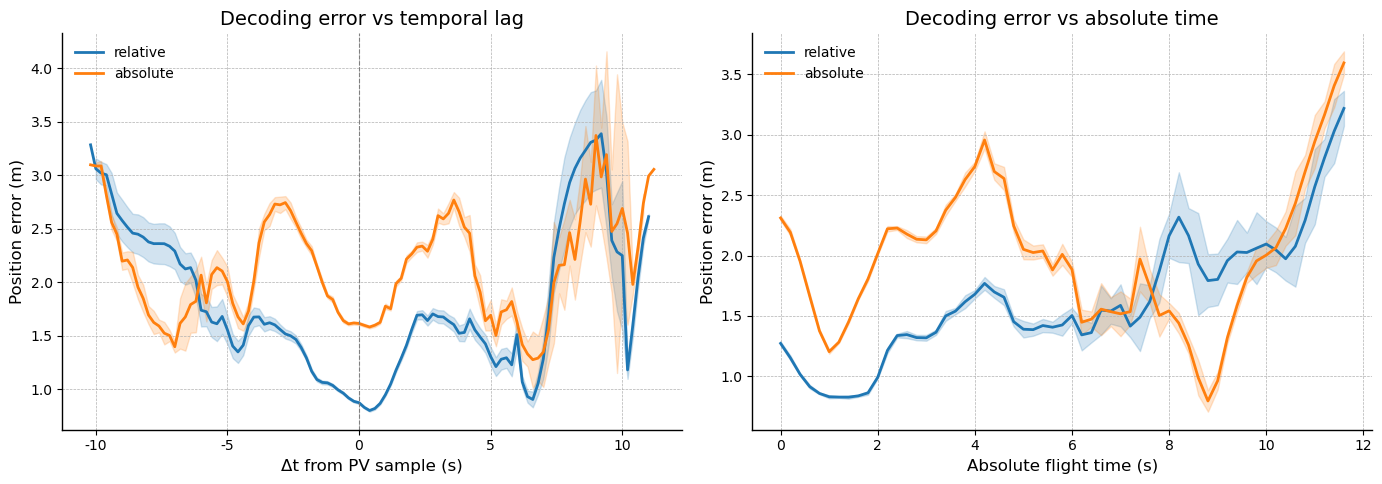

In [15]:
# Bin delta_t and compute mean error per bin
lag_bin_width = 0.2  # seconds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: error vs delta_t (relative time from PV sample)
ax = axes[0]
for mode, color in [('relative', 'C0'), ('absolute', 'C1')]:
    m = valid_df[valid_df['time_mode'] == mode].copy()
    m['lag_bin'] = (m['delta_t'] / lag_bin_width).round() * lag_bin_width
    agg = m.groupby('lag_bin')['err_3d'].agg(['mean', 'sem']).reset_index()
    ax.plot(agg['lag_bin'], agg['mean'], label=mode, color=color)
    ax.fill_between(agg['lag_bin'], agg['mean'] - agg['sem'],
                    agg['mean'] + agg['sem'], alpha=0.2, color=color)
ax.set_xlabel('Δt from PV sample (s)')
ax.set_ylabel('Position error (m)')
ax.set_title('Decoding error vs temporal lag')
ax.legend()
ax.axvline(0, color='gray', ls='--', lw=0.8)

# Panel 2: error vs t_abs (absolute flight time)
ax = axes[1]
for mode, color in [('relative', 'C0'), ('absolute', 'C1')]:
    m = valid_df[valid_df['time_mode'] == mode].copy()
    m['t_abs_bin'] = (m['t_abs'] / lag_bin_width).round() * lag_bin_width
    agg = m.groupby('t_abs_bin')['err_3d'].agg(['mean', 'sem']).reset_index()
    ax.plot(agg['t_abs_bin'], agg['mean'], label=mode, color=color)
    ax.fill_between(agg['t_abs_bin'], agg['mean'] - agg['sem'],
                    agg['mean'] + agg['sem'], alpha=0.2, color=color)
ax.set_xlabel('Absolute flight time (s)')
ax.set_ylabel('Position error (m)')
ax.set_title('Decoding error vs absolute time')
ax.legend()

plt.tight_layout()
plt.show()

## 9. R² per Spatial Dimension vs Time

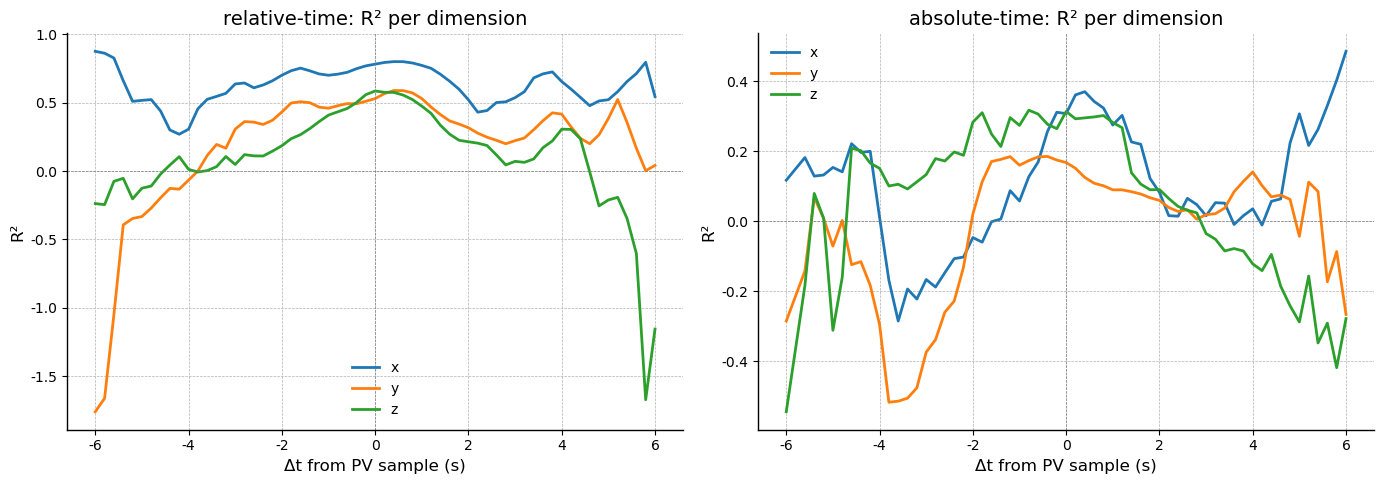

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, mode in zip(axes, ('relative', 'absolute')):
    m = valid_df[valid_df['time_mode'] == mode].copy()
    m['lag_bin'] = (m['delta_t'] / lag_bin_width).round() * lag_bin_width

    r2_records = []
    for lag, grp in m.groupby('lag_bin'):
        if len(grp) < 20:
            continue
        for dim, (true_col, pred_col) in enumerate(
            [('x_true', 'x_pred'), ('y_true', 'y_pred'), ('z_true', 'z_pred')]
        ):
            ss_res = ((grp[true_col] - grp[pred_col]) ** 2).sum()
            ss_tot = ((grp[true_col] - grp[true_col].mean()) ** 2).sum()
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0
            r2_records.append({'lag_bin': lag, 'dim': ['x', 'y', 'z'][dim], 'r2': r2})

    r2_df = pd.DataFrame(r2_records)
    for dim, color in [('x', 'C0'), ('y', 'C1'), ('z', 'C2')]:
        sub = r2_df[r2_df['dim'] == dim]
        ax.plot(sub['lag_bin'], sub['r2'], label=dim, color=color)
    ax.set_xlabel('Δt from PV sample (s)')
    ax.set_ylabel('R²')
    ax.set_title(f'{mode}-time: R² per dimension')
    ax.legend()
    ax.axhline(0, color='gray', ls='--', lw=0.5)
    ax.axvline(0, color='gray', ls='--', lw=0.5)

plt.tight_layout()
plt.show()

## 10. Validity AUC

relative: validity AUC = 0.9838
absolute: validity AUC = 0.9850


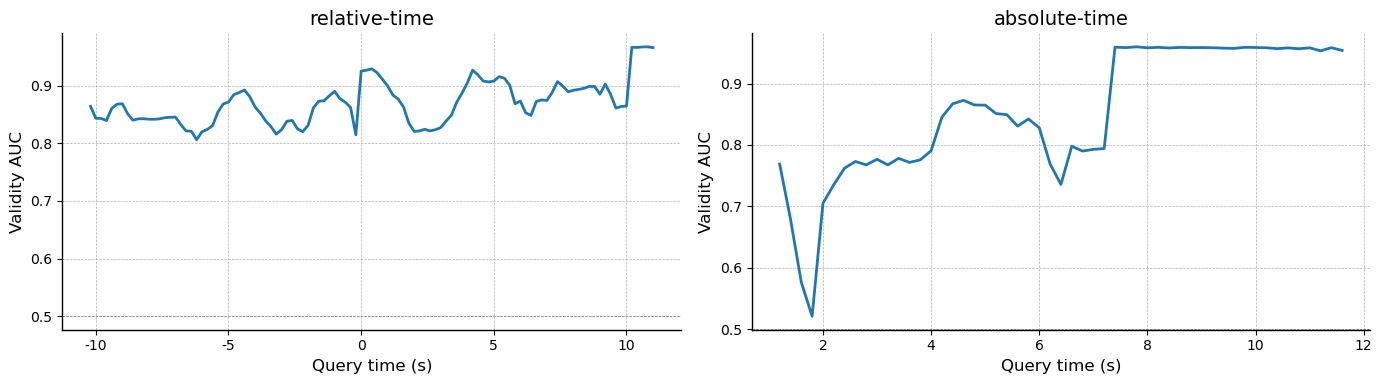

In [17]:
for mode in ('relative', 'absolute'):
    m = eval_df[eval_df['time_mode'] == mode]
    auc = roc_auc_score(m['valid_true'], m['valid_logit'])
    print(f'{mode}: validity AUC = {auc:.4f}')

# AUC as a function of query time
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, mode in zip(axes, ('relative', 'absolute')):
    m = eval_df[eval_df['time_mode'] == mode].copy()
    m['qt_bin'] = (m['query_time'] / lag_bin_width).round() * lag_bin_width
    auc_records = []
    for qt, grp in m.groupby('qt_bin'):
        if len(grp) < 20 or grp['valid_true'].nunique() < 2:
            continue
        auc_records.append({'qt': qt, 'auc': roc_auc_score(grp['valid_true'], grp['valid_logit'])})
    auc_df = pd.DataFrame(auc_records)
    ax.plot(auc_df['qt'], auc_df['auc'])
    ax.set_xlabel('Query time (s)')
    ax.set_ylabel('Validity AUC')
    ax.set_title(f'{mode}-time')
    ax.axhline(0.5, color='gray', ls='--', lw=0.5)
plt.tight_layout()
plt.show()

## 11. Trajectory Smoothness (Mean Squared Jerk)

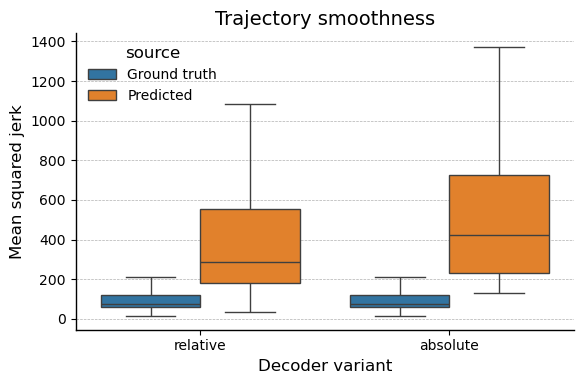

In [18]:
def compute_mean_squared_jerk(positions, dt):
    """MSJ of a (T, 3) trajectory."""
    if positions.shape[0] < 4:
        return np.nan
    vel = np.gradient(positions, dt, axis=0)
    acc = np.gradient(vel, dt, axis=0)
    jerk = np.gradient(acc, dt, axis=0)
    return float(np.mean(jerk ** 2))


def longest_contiguous_run(mask):
    """Return indices of the longest contiguous True segment in a boolean array."""
    valid_indices = np.where(mask)[0]
    if len(valid_indices) == 0:
        return np.array([], dtype=int)
    breaks = np.where(np.diff(valid_indices) != 1)[0]
    segments = np.split(valid_indices, breaks + 1)
    return max(segments, key=len)


# Compute MSJ for ground truth and both PV decoders, per flight
jerk_records = []

for mode in ('relative', 'absolute'):
    weights, config = best_models[mode][0]
    model = PerceiverIOTrajectoryDecoder(config).to(device)
    model.load_state_dict(weights)
    model.eval()

    ds = PVTrajectoryDataset(
        flights_test, config.time_mode, config.T_max, config.dt,
        samples_per_flight=1, rng=np.random.default_rng(0),
    )
    loader = DataLoader(ds, batch_size=256, shuffle=False, num_workers=0)

    with torch.no_grad():
        for pv, pos_tgt, vmask, t_sample_batch, fi_batch in loader:
            pv = pv.to(device)
            pos_pred, valid_logit, _, _ = model(pv)
            pos_pred = pos_pred.cpu().numpy()
            pos_tgt = pos_tgt.numpy()
            vmask = vmask.numpy()

            for b in range(pv.shape[0]):
                v = vmask[b].astype(bool)
                run = longest_contiguous_run(v)
                if len(run) < 4:
                    continue
                jerk_records.append({
                    'model': mode,
                    'msj_pred': compute_mean_squared_jerk(pos_pred[b, run], dt),
                    'msj_true': compute_mean_squared_jerk(pos_tgt[b, run], dt),
                })

jerk_df = pd.DataFrame(jerk_records)

fig, ax = plt.subplots(figsize=(6, 4))
melted = jerk_df.melt(id_vars='model', value_vars=['msj_true', 'msj_pred'],
                       var_name='source', value_name='msj')
melted['source'] = melted['source'].map({'msj_true': 'Ground truth', 'msj_pred': 'Predicted'})
sns.boxplot(data=melted, x='model', y='msj', hue='source', ax=ax, showfliers=False)
ax.set_ylabel('Mean squared jerk')
ax.set_xlabel('Decoder variant')
ax.set_title('Trajectory smoothness')
plt.tight_layout()
plt.show()

## 12. Comparison with Seq-to-Seq Transformer Decoder

Load the trained seq-to-seq transformer decoder from `decode-position-comparison.ipynb` and compare error vs absolute time.

In [ ]:
from digitalbat.models.decoder import Bat_Transformer_Decoder

# Load seq-to-seq decoder
s2s_study_path = f'./out/bat_decoder_seed_{seed}_optuna.pkl'
with open(s2s_study_path, 'rb') as f:
    s2s_study = pickle.load(f)
s2s_best = s2s_study.best_params
print(f'Seq-to-seq best params: {s2s_best}')

# Match decode-position-comparison.ipynb: build path from best_params so it
# stays in sync when optuna picks different hyperparameters.
substr = '_'.join(
    f'{k}_{v:.2f}' if isinstance(v, float) else f'{k}_{v}'
    for k, v in s2s_best.items()
)
s2s_model_path = f'./out/bat_decoder_seed_{seed}_{substr}.pth'

decoder_model = Bat_Transformer_Decoder(
    input_dim_dict=unit_num_dict, output_dim=3, num_heads=4,
    final_activation=nn.Identity(),
    latent_dim=s2s_best['latent_dim'], ff_dim=s2s_best['ff_dim'],
    num_layers=s2s_best['num_layers'],
    dropout_prob=s2s_best['dropout_prob'],
    readin_dropout=s2s_best['readin_dropout'],
    input_transform=s2s_best['input_transform'],
)
decoder_model.load_state_dict(
    torch.load(s2s_model_path, map_location=device, weights_only=True)
)
decoder_model = decoder_model.to(device)
decoder_model.eval()
print(f'Loaded seq-to-seq decoder from {s2s_model_path}')

In [ ]:
# Evaluate seq-to-seq decoder and build per-timepoint DataFrame
s2s_records = []
with torch.no_grad():
    for session_name, session_data in dataloaders['test'].items():
        bm = meta_info_dict['behavior_mean'][session_name].squeeze()
        bs = meta_info_dict['behavior_std'][session_name].squeeze()
        for batch in session_data:
            X = batch.spike.to(device)
            m = batch.mask.to(device)
            y_true_z = batch.behavior[:, :, :3].numpy()
            y_pred_z = decoder_model(session_name, X, m).cpu().numpy()
            mask_np = batch.mask.numpy().astype(bool)
            B, T = mask_np.shape
            y_true = y_true_z * bs[None, None, :3] + bm[None, None, :3]
            y_pred = y_pred_z * bs[None, None, :3] + bm[None, None, :3]
            fpi = batch.flight_path_index.numpy()

            for b in range(B):
                for t in range(T):
                    if not mask_np[b, t]:
                        continue
                    err = float(np.sqrt(((y_true[b, t] - y_pred[b, t]) ** 2).sum()))
                    s2s_records.append({
                        't_abs': t * dt,
                        'session': session_name,
                        'flight_id': int(fpi[b]),
                        'err_3d': err,
                        'x_true': float(y_true[b, t, 0]),
                        'y_true': float(y_true[b, t, 1]),
                        'z_true': float(y_true[b, t, 2]),
                        'x_pred': float(y_pred[b, t, 0]),
                        'y_pred': float(y_pred[b, t, 1]),
                        'z_pred': float(y_pred[b, t, 2]),
                    })

s2s_df = pd.DataFrame(s2s_records)
print(f'Seq-to-seq: median error = {s2s_df["err_3d"].median():.4f} m, '
      f'R² = {r2_score(s2s_df[["x_true", "y_true", "z_true"]], s2s_df[["x_pred", "y_pred", "z_pred"]]):.4f}')

In [ ]:
# Compare error vs absolute time for all three models
fig, ax = plt.subplots(figsize=(8, 5))

for mode, color, label in [
    ('relative', 'C0', 'PV-Perceiver (relative)'),
    ('absolute', 'C1', 'PV-Perceiver (absolute)'),
]:
    m = valid_df[valid_df['time_mode'] == mode].copy()
    m['t_abs_bin'] = (m['t_abs'] / lag_bin_width).round() * lag_bin_width
    agg = m.groupby('t_abs_bin')['err_3d'].agg(['mean', 'sem']).reset_index()
    ax.plot(agg['t_abs_bin'], agg['mean'], label=label, color=color)
    ax.fill_between(agg['t_abs_bin'], agg['mean'] - agg['sem'],
                    agg['mean'] + agg['sem'], alpha=0.15, color=color)

# Seq-to-seq
s2s_df_copy = s2s_df.copy()
s2s_df_copy['t_abs_bin'] = (s2s_df_copy['t_abs'] / lag_bin_width).round() * lag_bin_width
agg_s2s = s2s_df_copy.groupby('t_abs_bin')['err_3d'].agg(['mean', 'sem']).reset_index()
ax.plot(agg_s2s['t_abs_bin'], agg_s2s['mean'], label='Seq-to-seq transformer', color='C2')
ax.fill_between(agg_s2s['t_abs_bin'], agg_s2s['mean'] - agg_s2s['sem'],
                agg_s2s['mean'] + agg_s2s['sem'], alpha=0.15, color='C2')

ax.set_xlabel('Absolute flight time (s)')
ax.set_ylabel('Position error (m)')
ax.set_title('Three-way model comparison: error vs absolute time')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Trajectory smoothness comparison including seq-to-seq
s2s_jerk_records = []
with torch.no_grad():
    for session_name, session_data in dataloaders['test'].items():
        bm = meta_info_dict['behavior_mean'][session_name].squeeze()
        bs = meta_info_dict['behavior_std'][session_name].squeeze()
        for batch in session_data:
            X = batch.spike.to(device)
            m_batch = batch.mask.to(device)
            y_true_z = batch.behavior[:, :, :3].numpy()
            y_pred_z = decoder_model(session_name, X, m_batch).cpu().numpy()
            mask_np = batch.mask.numpy().astype(bool)
            B, T = mask_np.shape
            y_true = y_true_z * bs[None, None, :3] + bm[None, None, :3]
            y_pred = y_pred_z * bs[None, None, :3] + bm[None, None, :3]

            for b in range(B):
                v = mask_np[b]
                if v.sum() < 4:
                    continue
                s2s_jerk_records.append({
                    'model': 'seq-to-seq',
                    'msj_pred': compute_mean_squared_jerk(y_pred[b, v], dt),
                    'msj_true': compute_mean_squared_jerk(y_true[b, v], dt),
                })

all_jerk = pd.concat([jerk_df, pd.DataFrame(s2s_jerk_records)], ignore_index=True)
melted = all_jerk.melt(id_vars='model', value_vars=['msj_true', 'msj_pred'],
                        var_name='source', value_name='msj')
melted['source'] = melted['source'].map({'msj_true': 'Ground truth', 'msj_pred': 'Predicted'})

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=melted, x='model', y='msj', hue='source', ax=ax, showfliers=False)
ax.set_ylabel('Mean squared jerk')
ax.set_xlabel('Decoder')
ax.set_title('Trajectory smoothness: all three decoders')
plt.tight_layout()
plt.show()

## 13. Relative vs Absolute: Per-Example Comparison

In [ ]:
# For matched (flight, t_sample) pairs, compare relative vs absolute error
rel_valid = valid_df[valid_df['time_mode'] == 'relative'].copy()
abs_valid = valid_df[valid_df['time_mode'] == 'absolute'].copy()

# Align on (flight_idx, t_sample, t_abs) to get matched predictions
merged = rel_valid.merge(
    abs_valid, on=['flight_idx', 't_sample', 't_abs'], suffixes=('_rel', '_abs'),
    how='inner',
)
merged['err_diff'] = merged['err_3d_rel'] - merged['err_3d_abs']  # positive = relative worse

print(f'Matched time points: {len(merged)}')
print(f'Mean error diff (rel - abs): {merged["err_diff"].mean():.4f} m')
print(f'Relative wins: {(merged["err_diff"] < 0).sum()}, '
      f'Absolute wins: {(merged["err_diff"] > 0).sum()}')

# Error diff as a function of delta_t
merged['lag_bin'] = (merged['delta_t_rel'] / lag_bin_width).round() * lag_bin_width

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
agg = merged.groupby('lag_bin')['err_diff'].agg(['mean', 'sem']).reset_index()
ax.plot(agg['lag_bin'], agg['mean'], color='C3')
ax.fill_between(agg['lag_bin'], agg['mean'] - agg['sem'],
                agg['mean'] + agg['sem'], alpha=0.2, color='C3')
ax.axhline(0, color='gray', ls='--')
ax.set_xlabel('Δt from PV sample (s)')
ax.set_ylabel('Error(relative) − Error(absolute) (m)')
ax.set_title('Positive = absolute is better')

ax = axes[1]
sns.histplot(merged['err_diff'], bins=50, ax=ax, kde=True)
ax.axvline(0, color='gray', ls='--')
ax.set_xlabel('Error(relative) − Error(absolute) (m)')
ax.set_title('Per-timepoint error difference')

plt.tight_layout()
plt.show()

## 14. Encoder Attention Maps (Interpretability)

In [ ]:
# Visualize encoder attention: which neurons each latent slot attends to
weights, config = best_models['relative'][0]
model = PerceiverIOTrajectoryDecoder(config).to(device)
model.load_state_dict(weights)
model.eval()

# Get attention weights from a batch of test examples
ds = PVTrajectoryDataset(
    flights_test, config.time_mode, config.T_max, config.dt,
    samples_per_flight=1, rng=np.random.default_rng(0),
)
loader = DataLoader(ds, batch_size=min(100, len(ds)), shuffle=False)
pv_batch = next(iter(loader))[0].to(device)

with torch.no_grad():
    _, _, enc_attn, dec_attn = model(pv_batch)

# Average encoder attention across batch and heads: (L, N)
enc_attn_mean = enc_attn.mean(dim=(0, 1)).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
im = ax.imshow(enc_attn_mean, aspect='auto', cmap='viridis')
ax.set_xlabel('Neuron index')
ax.set_ylabel('Latent slot')
ax.set_title('Encoder attention (avg over batch & heads)')
plt.colorbar(im, ax=ax, label='Attention weight')

# Cluster latent slots by attention profile
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
Z = linkage(enc_attn_mean, method='ward')
ax = axes[1]
dendrogram(Z, ax=ax, leaf_font_size=8)
ax.set_xlabel('Latent slot')
ax.set_ylabel('Ward distance')
ax.set_title('Latent slot clustering by neuron attention')

plt.tight_layout()
plt.show()

## 15. Decoder Attention Maps

In [ ]:
# Decoder attention: which latent slots do past/present/future queries attend to?
dec_attn_mean = dec_attn.mean(dim=(0, 1)).cpu().numpy()  # (O, L)

query_times = ds.query_times
O = len(query_times)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
im = ax.imshow(dec_attn_mean.T, aspect='auto', cmap='viridis',
               extent=[query_times[0], query_times[-1], dec_attn_mean.shape[1] - 0.5, -0.5])
ax.set_xlabel('Query time (s)')
ax.set_ylabel('Latent slot')
ax.set_title('Decoder attention (avg over batch & heads)')
plt.colorbar(im, ax=ax, label='Attention weight')
ax.axvline(0, color='white', ls='--', lw=0.8)

# Compare past vs future attention profiles
ax = axes[1]
past_mask = query_times < -0.5
present_mask = np.abs(query_times) <= 0.5
future_mask = query_times > 0.5

for mask, label, color in [
    (past_mask, 'Past (< -0.5s)', 'C0'),
    (present_mask, 'Present (±0.5s)', 'C1'),
    (future_mask, 'Future (> 0.5s)', 'C2'),
]:
    if mask.sum() > 0:
        profile = dec_attn_mean[mask].mean(axis=0)
        ax.bar(np.arange(len(profile)) + {'C0': -0.25, 'C1': 0, 'C2': 0.25}[color],
               profile, width=0.25, label=label, color=color, alpha=0.7)

ax.set_xlabel('Latent slot')
ax.set_ylabel('Mean attention weight')
ax.set_title('Decoder attention by temporal region')
ax.legend()

plt.tight_layout()
plt.show()